# Kaggle data vs external data, side by side

Our models first learn from **external data** (texts other people generated from the same 18 models), then get a short polish on Kaggle's `train.csv`. This notebook puts the datasets next to each other so you can see where they agree and where they drift.

| Name here | File | Rows | Used for |
|---|---|---|---|
| **Kaggle** | `data/train.csv` | 2,699 | stage 2 (the polish), all scoring |
| **Pool 92k** | `pool_cont2` | 92,485 | stage 1 of the main model (s4, weight 0.5 in v9) |
| **Pool 60k** | `pool_typo_60k` | 60,000 | stage 1 of the older Qwen members |
| **Hostlike** | `hostlike` | 6,897 | added to stage 1 for one older member |

**How to read the colours**
- **Amounts** (shares, lengths, similarities) use one colour going from light to dark: darker means more.
- **Differences** (external minus Kaggle) use blue for "less than Kaggle", grey for "the same", orange for "more than Kaggle". Grey everywhere would mean a perfect match.
- Model names are coloured by family (Claude blue, Gemini orange, GPT green, GLM yellow, Kimi pink, Qwen dark green).

**Fair comparison:** for every feature chart, each external set is cut down to at most 150 texts per model, the same as Kaggle. So a difference never comes from one set simply having more GPT texts.

In [1]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
warnings.filterwarnings("ignore")

ROOT = "../"
sys.path.insert(0, ROOT + "features")
import style_features as SF

FILES = {"Kaggle": "data/train.csv", "Pool 92k": "data/processed/pool_cont2.parquet",
         "Pool 60k": "data/processed/pool_typo_60k.parquet", "Hostlike": "data/processed/hostlike.parquet"}
FULL = {k: (pd.read_csv(ROOT + f) if f.endswith(".csv") else pd.read_parquet(ROOT + f, columns=["text", "model"]))
        for k, f in FILES.items()}
for d in FULL.values(): d["text"] = d.text.fillna("").astype(str)
SETS = list(FULL)
EXT = SETS[1:]

FAMILIES = ["claude", "gemini", "gpt", "glm", "kimi", "qwen"]
FAM_COLOR = dict(zip(FAMILIES, ["#2a78d6", "#eb6834", "#1baf7a", "#c08400", "#e87ba4", "#008300"]))
fam = lambda m: next(f for f in FAMILIES if m.startswith(f))
MODELS = sorted(FULL["Kaggle"].model.unique(), key=lambda m: (FAMILIES.index(fam(m)), m))
for k in EXT: FULL[k] = FULL[k][FULL[k].model.isin(MODELS)]

SEQ = LinearSegmentedColormap.from_list("seq", ["#f5f8fc", "#b9d3f2", "#5b93db", "#1c5cab", "#0b2f5e"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#ecebe6", "#f3a17f", "#b8431a"])
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def colour_labels(ax, axis="y"):
    for lab in (ax.get_yticklabels() if axis == "y" else ax.get_xticklabels()):
        t = lab.get_text()
        if any(t.startswith(f) for f in FAMILIES):
            lab.set_color(FAM_COLOR[fam(t)]); lab.set_fontweight("bold")

def heat(ax, M, rows, cols, cmap, norm=None, vmin=None, vmax=None, fmt="{:.2f}", annot=True, cbar=True, label=""):
    """Heatmap with numbers in the cells; text turns white on dark cells so it stays readable."""
    M = np.asarray(M, dtype=float)
    im = ax.imshow(M, cmap=cmap, norm=norm, vmin=None if norm else vmin, vmax=None if norm else vmax, aspect="auto")
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(rows)), rows)
    ax.set_xticks(np.arange(-.5, len(cols)), minor=True); ax.set_yticks(np.arange(-.5, len(rows)), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
    for s in ax.spines.values(): s.set_visible(False)
    if annot:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M[i, j]):
                    r, g, b, _ = im.cmap(im.norm(M[i, j]))
                    ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=8,
                            color="white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#222")
    if cbar: plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label=label)
    colour_labels(ax, "y"); colour_labels(ax, "x")
    return im

# class-matched samples: at most 150 texts per model from every set (Kaggle has 150 per model)
S = {"Kaggle": FULL["Kaggle"][["text", "model"]].copy()}
for k in EXT:
    d = FULL[k]
    S[k] = pd.concat([d[d.model == m].sample(min(150, (d.model == m).sum()), random_state=0) for m in MODELS])
NAMES = list(SF.NAMES)
F = {k: pd.DataFrame([SF.extract(t) for t in s.text], columns=NAMES, index=s.index) for k, s in S.items()}
VARY = [n for n in NAMES if F["Kaggle"][n].std() > 0]
for k in SETS: print(f"{k:9s} {len(FULL[k]):6d} texts in total, {len(S[k])} in the class-matched sample")
print(f"{len(NAMES)} style features, {len(VARY)} vary inside Kaggle")

Kaggle      2699 texts in total, 2699 in the class-matched sample
Pool 92k   92485 texts in total, 2700 in the class-matched sample
Pool 60k   60000 texts in total, 2700 in the class-matched sample
Hostlike    6897 texts in total, 2700 in the class-matched sample
316 style features, 290 vary inside Kaggle


## 1. How many texts per model?

Each cell is the share of that dataset's texts written by that model. A perfectly balanced set has 5.6% everywhere (1 of 18): grey. Blue = fewer texts than a fair share, orange = more.

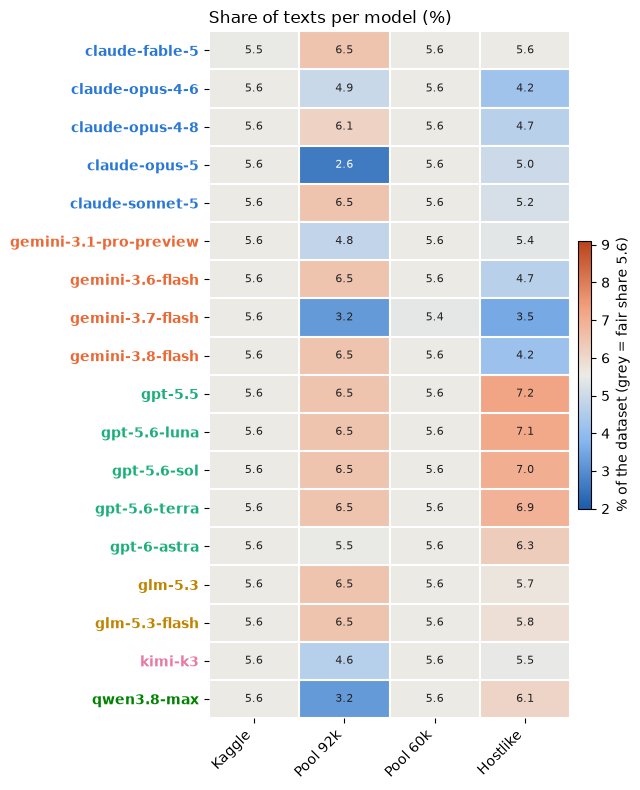

In [2]:
share = pd.DataFrame({k: FULL[k].model.value_counts(normalize=True).reindex(MODELS).fillna(0) * 100 for k in SETS})
fig, ax = plt.subplots(figsize=(6.5, 8))
heat(ax, share.values, MODELS, SETS, DIV, norm=TwoSlopeNorm(100 / 18, 2, 9.1), fmt="{:.1f}",
     label="% of the dataset (grey = fair share 5.6)")
ax.set_title("Share of texts per model (%)", loc="left"); plt.tight_layout(); plt.show()

**What this shows:**
- **Pool 60k** was sampled to be balanced: grey everywhere, like Kaggle.
- **Pool 92k is uneven.** claude-opus-5 has only 2.6%, gemini-3.7-flash and qwen3.8-max 3.2%, kimi-k3 4.6%, while most others have 6.5%.
- **Hostlike** has extra GPT texts (6.3% to 7.2%) and few Geminis (gemini-3.7-flash 3.5%, gemini-3.8-flash 4.2%).
- So **gemini-3.7-flash is short of texts in both sets that fed the main model's training**, and it is one of the models we recognise worst. The main model saw fewer examples of it during its first stage.

## 2. How long are the texts?

Left: the spread of lengths in each dataset (the middle 50% is the box, the line is the median).
Right: the median length per model, divided by Kaggle's median for the same model. **1.00 (grey) means the same length as Kaggle**, blue means shorter, orange means longer.

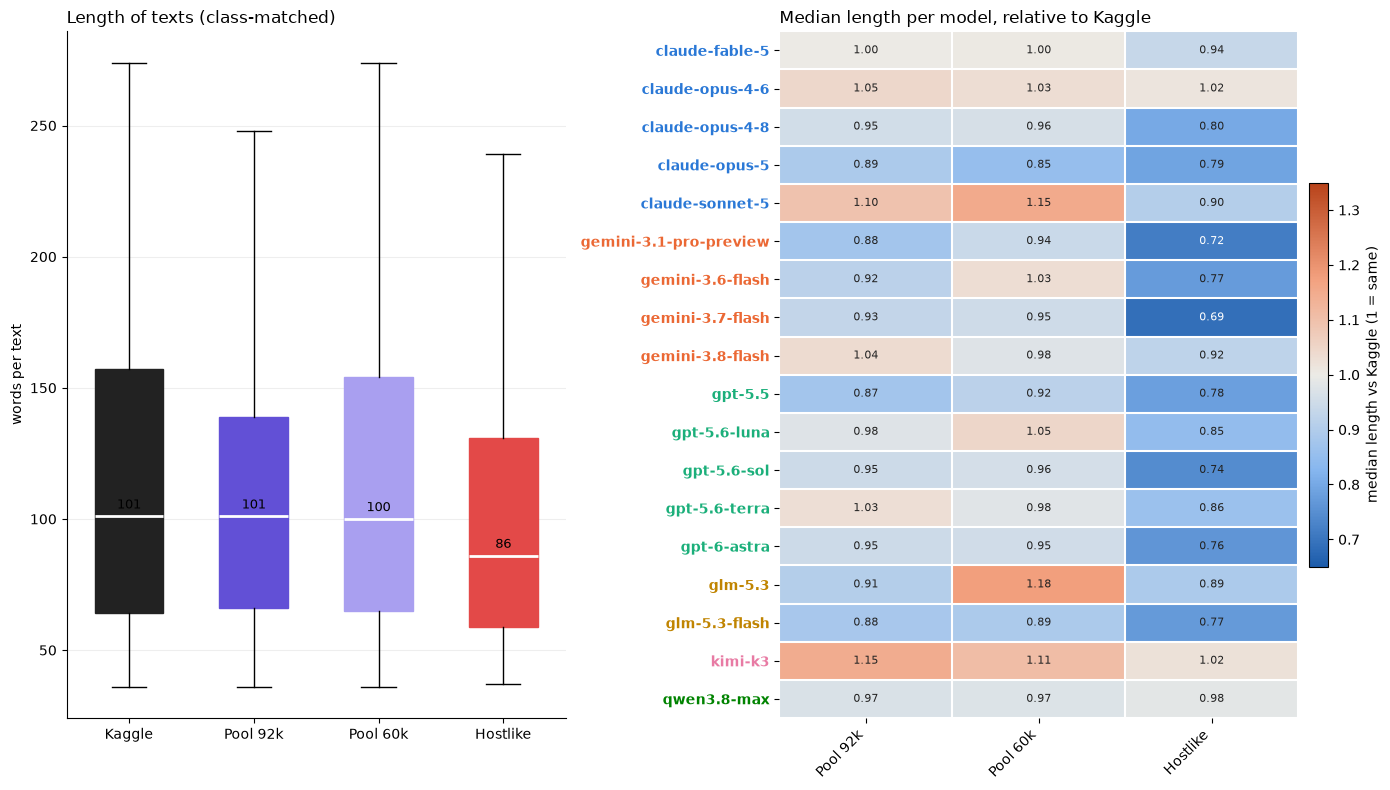

Kaggle median words per model: {'claude-fable-5': 100, 'claude-opus-4-6': 98, 'claude-opus-4-8': 109, 'claude-opus-5': 116, 'claude-sonnet-5': 99, 'gemini-3.1-pro-preview': 104, 'gemini-3.6-flash': 95, 'gemini-3.7-flash': 101, 'gemini-3.8-flash': 84, 'gpt-5.5': 103, 'gpt-5.6-luna': 104, 'gpt-5.6-sol': 111, 'gpt-5.6-terra': 100, 'gpt-6-astra': 105, 'glm-5.3': 96, 'glm-5.3-flash': 112, 'kimi-k3': 89, 'qwen3.8-max': 98}


In [3]:
words = {k: S[k].text.str.split().str.len() for k in SETS}
fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
DS_COLOR = {"Kaggle": "#222222", "Pool 92k": "#6250d6", "Pool 60k": "#a99ff0", "Hostlike": "#e34948"}
bp = ax.boxplot([words[k] for k in SETS], vert=True, widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": "white", "lw": 2})
for p, k in zip(bp["boxes"], SETS): p.set_facecolor(DS_COLOR[k]); p.set_edgecolor(DS_COLOR[k])
ax.set_xticks(range(1, 5), SETS); ax.set_ylabel("words per text"); ax.grid(axis="y", color="#eee"); ax.set_axisbelow(True)
for i, k in enumerate(SETS, 1): ax.text(i, np.median(words[k]) + 3, f"{np.median(words[k]):.0f}", ha="center", fontsize=9)
ax.set_title("Length of texts (class-matched)", loc="left")
med = pd.DataFrame({k: words[k].groupby(S[k].model).median().reindex(MODELS) for k in SETS})
ratio = med[EXT].div(med["Kaggle"], axis=0)
heat(axes[1], ratio.values, MODELS, EXT, DIV, norm=TwoSlopeNorm(1.0, 0.65, 1.35), fmt="{:.2f}",
     label="median length vs Kaggle (1 = same)")
axes[1].set_title("Median length per model, relative to Kaggle", loc="left")
plt.tight_layout(); plt.show()
print("Kaggle median words per model:", med["Kaggle"].astype(int).to_dict())

**What this shows:**
- Overall, the two pools have Kaggle's length (median 101 and 100 words vs 101). **Hostlike is shorter** (86): blue in almost every row of the right panel, down to 0.69 for gemini-3.7-flash.
- Per model, the pools mostly sit within 10% of Kaggle. The exceptions: kimi-k3 is longer outside (1.15 and 1.11), and in Pool 60k glm-5.3 (1.18) and claude-sonnet-5 (1.15).
- **A clue that gets lost:** in Kaggle, gemini-3.7-flash writes clearly longer texts than gemini-3.8-flash (median 101 vs 84 words). In Pool 92k the gap shrinks to about 94 vs 87, and in hostlike it even flips (about 70 vs 77). So the external data barely teaches "longer means 3.7", and 3.7 vs 3.8 is one of our worst mix-ups.

## 3. Writing habits, model by model

Six habits from our style features. In each small heatmap, a row is a model and a column is a dataset, and the colour is the raw value (darker = more of that habit). If the external data copies Kaggle, **each row has one even colour from left to right**.

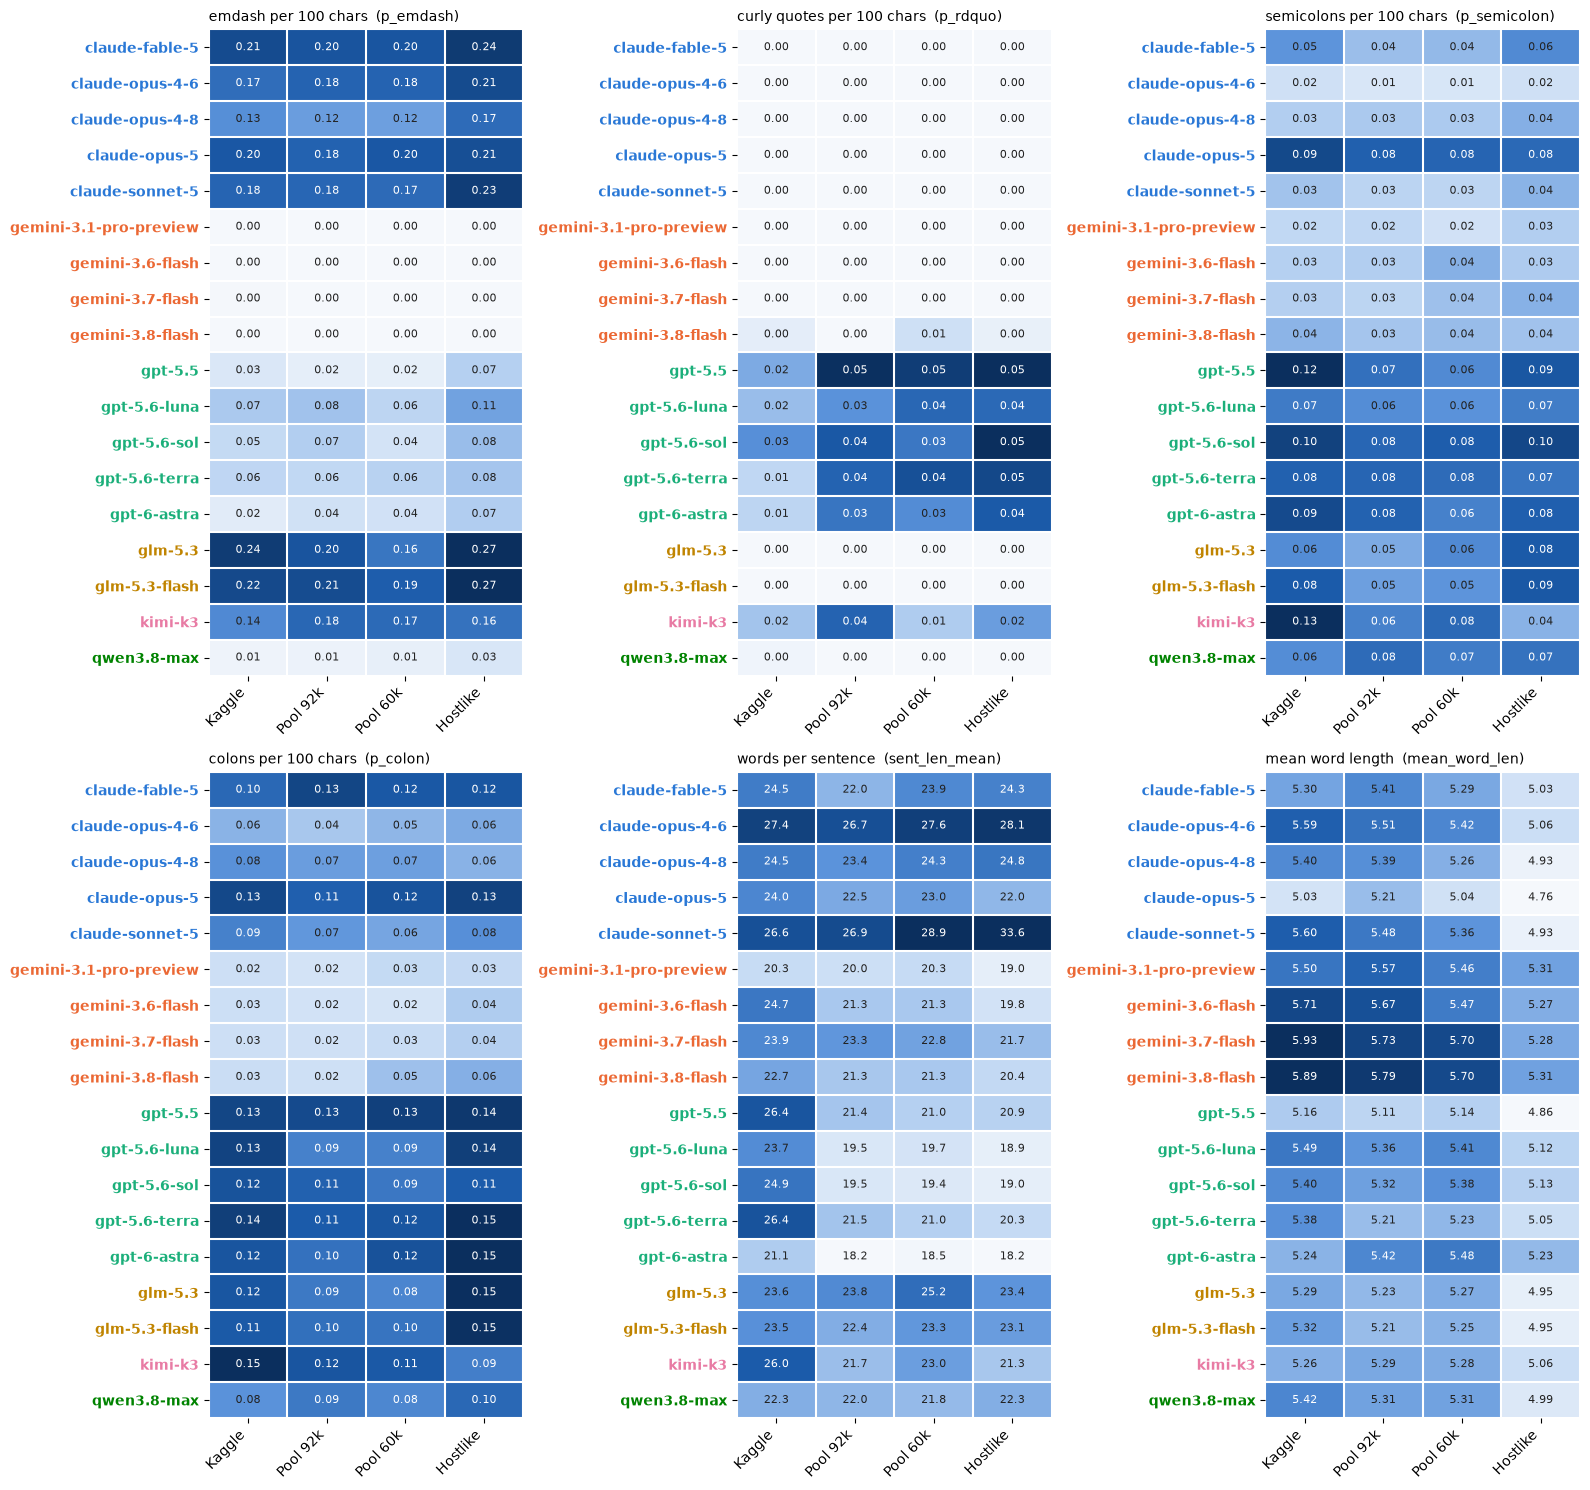

habit columns used: {'emdash per 100 chars': 'p_emdash', 'curly quotes per 100 chars': 'p_rdquo', 'semicolons per 100 chars': 'p_semicolon', 'colons per 100 chars': 'p_colon', 'words per sentence': 'sent_len_mean', 'mean word length': 'mean_word_len'}


In [4]:
HABITS = {"emdash per 100 chars": "p_emdash", "curly quotes per 100 chars": "p_rdquo",
          "semicolons per 100 chars": "p_semicolon", "colons per 100 chars": "p_colon",
          "words per sentence": None, "mean word length": "mean_word_len"}
sent_col = next((n for n in NAMES if "sent" in n and "mean" in n), None)
HABITS["words per sentence"] = sent_col
HABITS = {k: v for k, v in HABITS.items() if v in NAMES}
fig, axes = plt.subplots(2, 3, figsize=(16, 15))
for ax, (title, col) in zip(axes.ravel(), HABITS.items()):
    M = pd.DataFrame({k: F[k][col].groupby(S[k].model).mean().reindex(MODELS) for k in SETS})
    lo = 0 if M.values.min() < 1 else float(np.nanpercentile(M.values, 2))  # lengths: scale from the smallest value
    heat(ax, M.values, MODELS, SETS, SEQ, vmin=lo, vmax=float(np.nanpercentile(M.values, 98)) or 1,
         fmt="{:.2f}" if M.values.max() < 10 else "{:.1f}", cbar=False)
    ax.set_title(f"{title}  ({col})", loc="left", fontsize=10)
for ax in axes.ravel()[len(HABITS):]: ax.axis("off")
plt.tight_layout(); plt.show()
print("habit columns used:", HABITS)

**What this shows:**
- **Family rules hold everywhere:** Gemini never uses em dashes; Claude, GLM and Gemini never use curly quotes; Claude and GLM use the most em dashes. The rows are evenly coloured for these.
- **Curly quotes in GPT:** 2 to 4 times more common outside (for example gpt-5.6-terra 0.01 in Kaggle, 0.04 outside). A habit the external data exaggerates.
- **Semicolons:** kimi-k3 uses about twice as many in Kaggle (0.13) as outside (0.04 to 0.08); gpt-5.5 too (0.12 vs 0.07 to 0.09).
- **Sentence length:** GPT models write **longer sentences in Kaggle** (24 to 26 words vs 18 to 22 outside), and so does kimi-k3 (26 vs 21 to 23). That is a clear change in setting, not noise.
- **Word length:** hostlike uses shorter words for every model (about 5.0 vs 5.3 to 5.9), consistent with simpler topics.

## 4. Which features drift, and for which models?

For every model and feature: **(external mean minus Kaggle mean) divided by the spread** (the standardised difference). 0 (grey) means the same, plus or minus 0.5 is a clear shift, plus or minus 1 is large. The 30 features shown are the ones that drift most on average across the three external sets.

For scale: with 150 texts on each side, pure chance alone gives differences of about plus or minus 0.1, so only cells with clear colour matter.

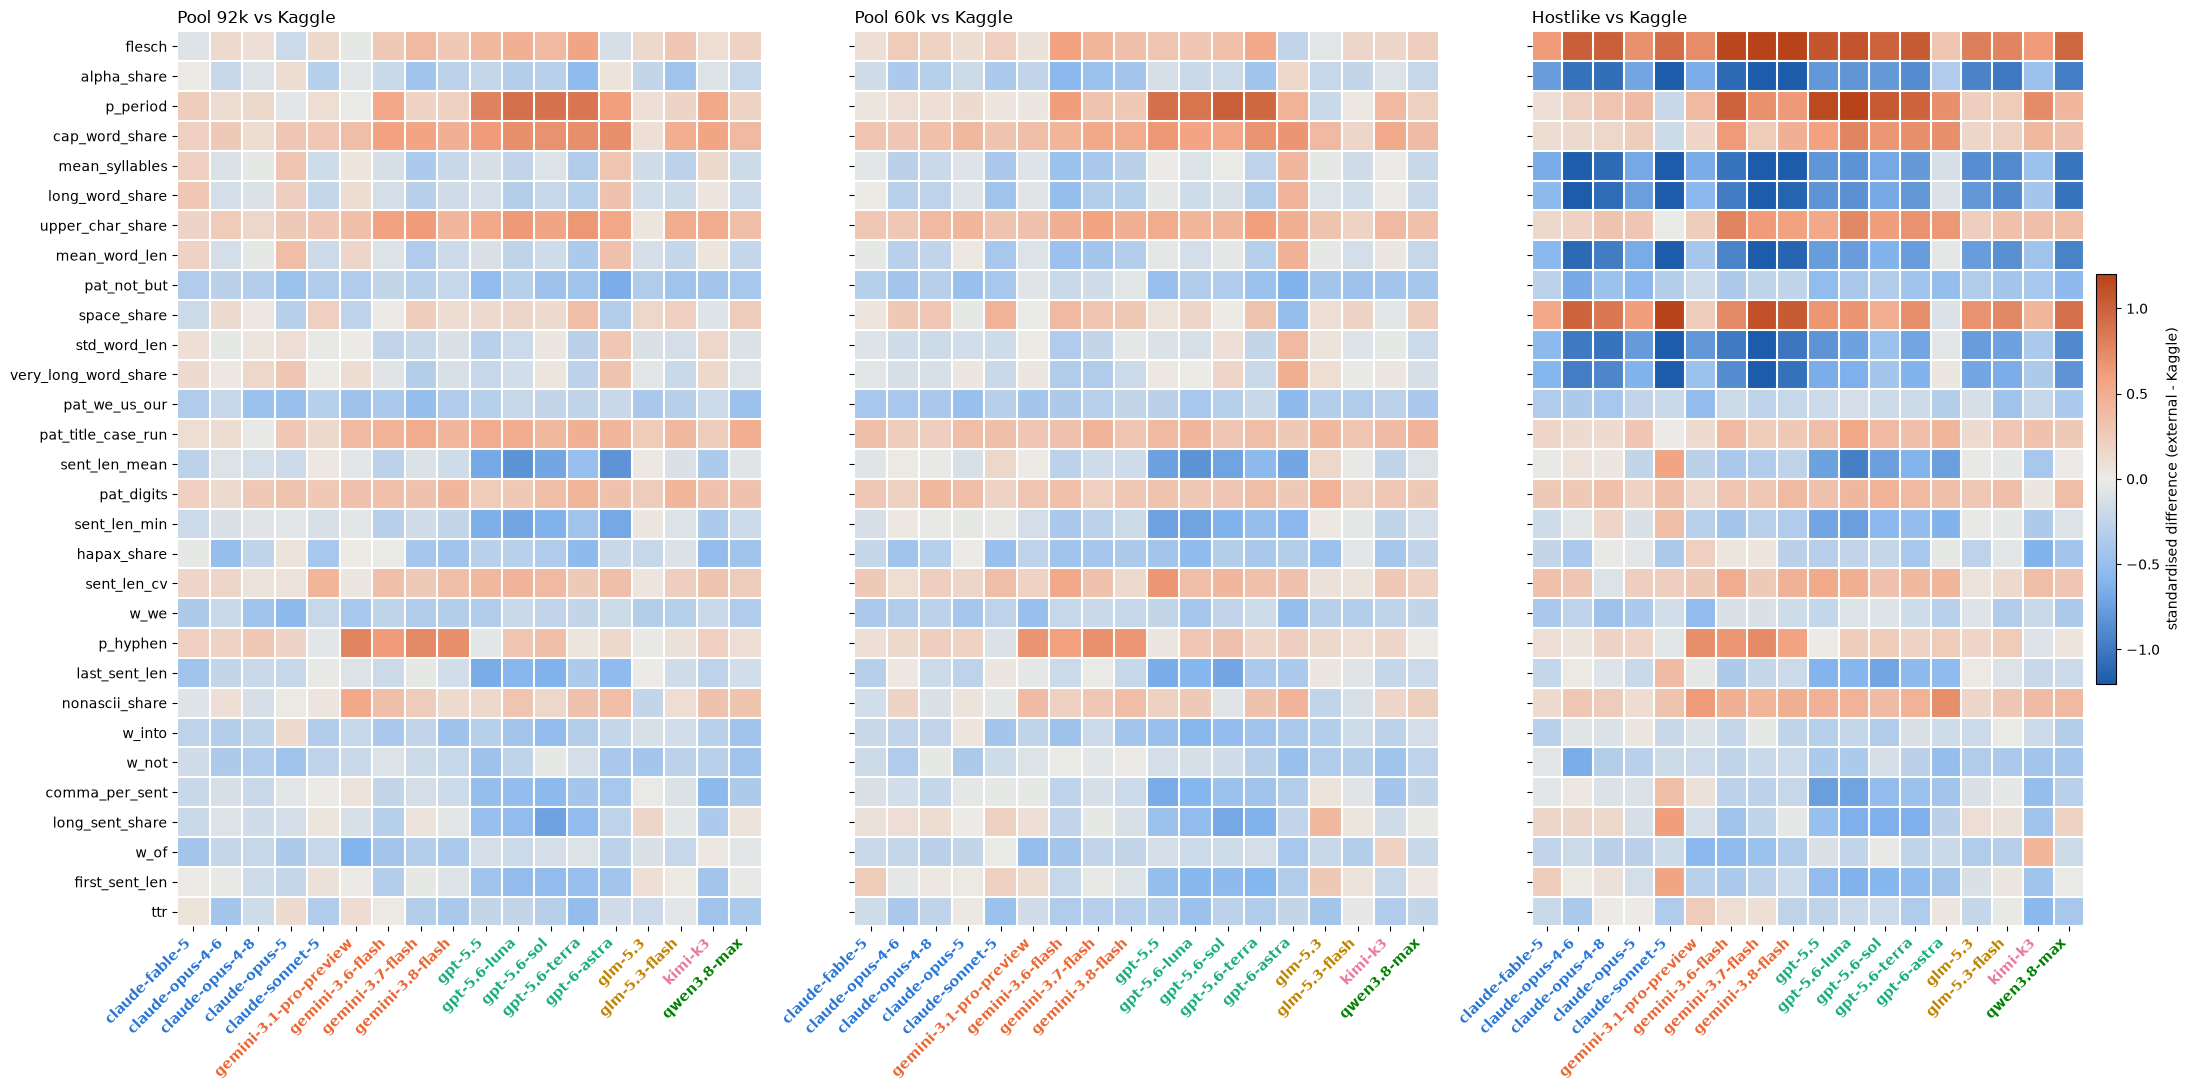

          features x models with |diff| > 0.5 (%)  mean |diff|
Pool 92k                                     1.51         0.13
Pool 60k                                     1.38         0.13
Hostlike                                     4.56         0.16


In [5]:
def smd(a, b):
    return (b.mean(0) - a.mean(0)) / (np.sqrt((a.var(0) + b.var(0)) / 2) + 1e-9)
DR = {}
for k in EXT:
    DR[k] = pd.DataFrame({m: smd(F["Kaggle"].loc[S["Kaggle"].model == m, VARY].to_numpy(),
                                 F[k].loc[S[k].model == m, VARY].to_numpy()) for m in MODELS}, index=VARY)
top = pd.concat([DR[k].abs().mean(1) for k in EXT], axis=1).mean(1).sort_values(ascending=False).head(30).index
fig, axes = plt.subplots(1, 3, figsize=(22, 11), sharey=True)
for ax, k in zip(axes, EXT):
    heat(ax, DR[k].loc[top].values, list(top), MODELS, DIV, norm=TwoSlopeNorm(0, -1.2, 1.2), annot=False,
         cbar=(k == EXT[-1]), label="standardised difference (external - Kaggle)")
    ax.set_title(f"{k} vs Kaggle", loc="left")
plt.tight_layout(); plt.show()
summ = pd.DataFrame({k: {"features x models with |diff| > 0.5 (%)": 100 * (DR[k].abs() > 0.5).values.mean(),
                         "mean |diff|": DR[k].abs().values.mean()} for k in EXT}).T
print(summ.round(2).to_string())

**What this shows:**
- **The two pools are close to Kaggle:** only about 1.5% of the (feature, model) cells shift by more than 0.5. **Hostlike drifts three times as much** (4.6%).
- **Horizontal bands** (a feature that shifts the same way for every model) point to a dataset-wide change, most likely the topics: outside texts have more capital letters, digits and title-case runs (names and numbers), fewer "we/us/our", and fewer "not X but Y".
- **Blocks under one family** are model-specific drift: GPT outside has more periods and shorter sentences (the blue `sent_len` rows under the GPT columns), and Gemini uses more hyphens outside.
- **Hostlike** has strong bands in word length and readability (`flesch`, `mean_syllables`, `long_word_share`): its prompts ask for simpler, everyday writing.

## 5. Where do the texts sit in "style space"?

All 290 style features squeezed into 2 dimensions (PCA, fitted on Kaggle only). Each panel is a density map: **darker = more texts there**. Same axes in every panel, so you can compare the shapes directly. The red line outlines where Kaggle is densest (half its peak density), drawn on every panel for reference. Caution: 2 axes keep only a small part of the 290 features, so this is a rough picture; sections 4 and 7 are the precise ones.

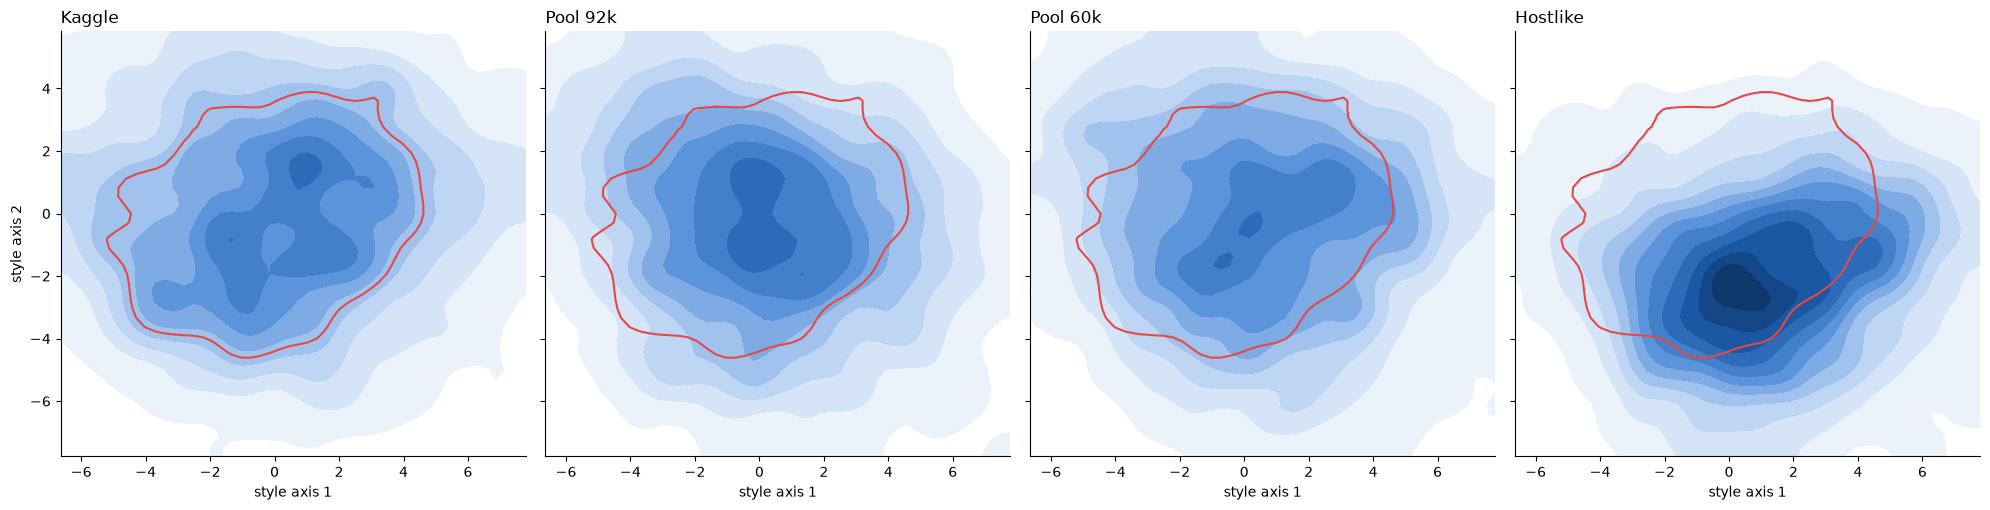

share of style variation the 2 axes keep: [0.041 0.03 ]


In [6]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(np.log1p(F["Kaggle"][VARY].clip(lower=0)))
pca = PCA(2, random_state=0).fit(sc.transform(np.log1p(F["Kaggle"][VARY].clip(lower=0))))
P = {k: pca.transform(sc.transform(np.log1p(F[k][VARY].clip(lower=0)))) for k in SETS}
lim = np.percentile(np.vstack(list(P.values())), [1, 99], axis=0)
from scipy.ndimage import gaussian_filter
def dens(p):  # smoothed 2-D histogram, so the shapes are readable instead of grainy
    h, xe, ye = np.histogram2d(*p.T, bins=50, range=[lim[:, 0], lim[:, 1]], density=True)
    return gaussian_filter(h, 2.0), xe, ye
H0, xe, ye = dens(P["Kaggle"])
xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
vmax = max(dens(P[k])[0].max() for k in SETS)
fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), sharex=True, sharey=True)
for ax, k in zip(axes, SETS):
    H = dens(P[k])[0]
    ax.contourf(xc, yc, H.T, levels=np.linspace(vmax * 0.03, vmax, 12), cmap=SEQ, extend="neither")
    ax.contour(xc, yc, H0.T, levels=[H0.max() * 0.5], colors="#e34948", linewidths=1.5)
    ax.set_title(k, loc="left"); ax.set_xlabel("style axis 1")
axes[0].set_ylabel("style axis 2")
plt.tight_layout(); plt.show()
print("share of style variation the 2 axes keep:", pca.explained_variance_ratio_.round(3))

**What this shows:**
- **Both pools cover the same area as Kaggle**: their dense region sits inside the red Kaggle outline.
- **Hostlike is shifted down and to the right**, and its peak sits near the lower edge of Kaggle's dense region. That is the shorter-words, easier-reading shift from section 4.
- Remember that this map keeps only about 7% of the style variation, so it shows the big shifts only.

## 6. Who resembles whom?

For each dataset: how similar every model's average style is to every other model's (cosine similarity of the model averages, each measured from its own dataset's average, so a shift of a whole dataset does not count). Dark squares along the diagonal = families. The last row shows **external minus Kaggle**: orange means two models look more alike outside than in Kaggle, blue means less alike.

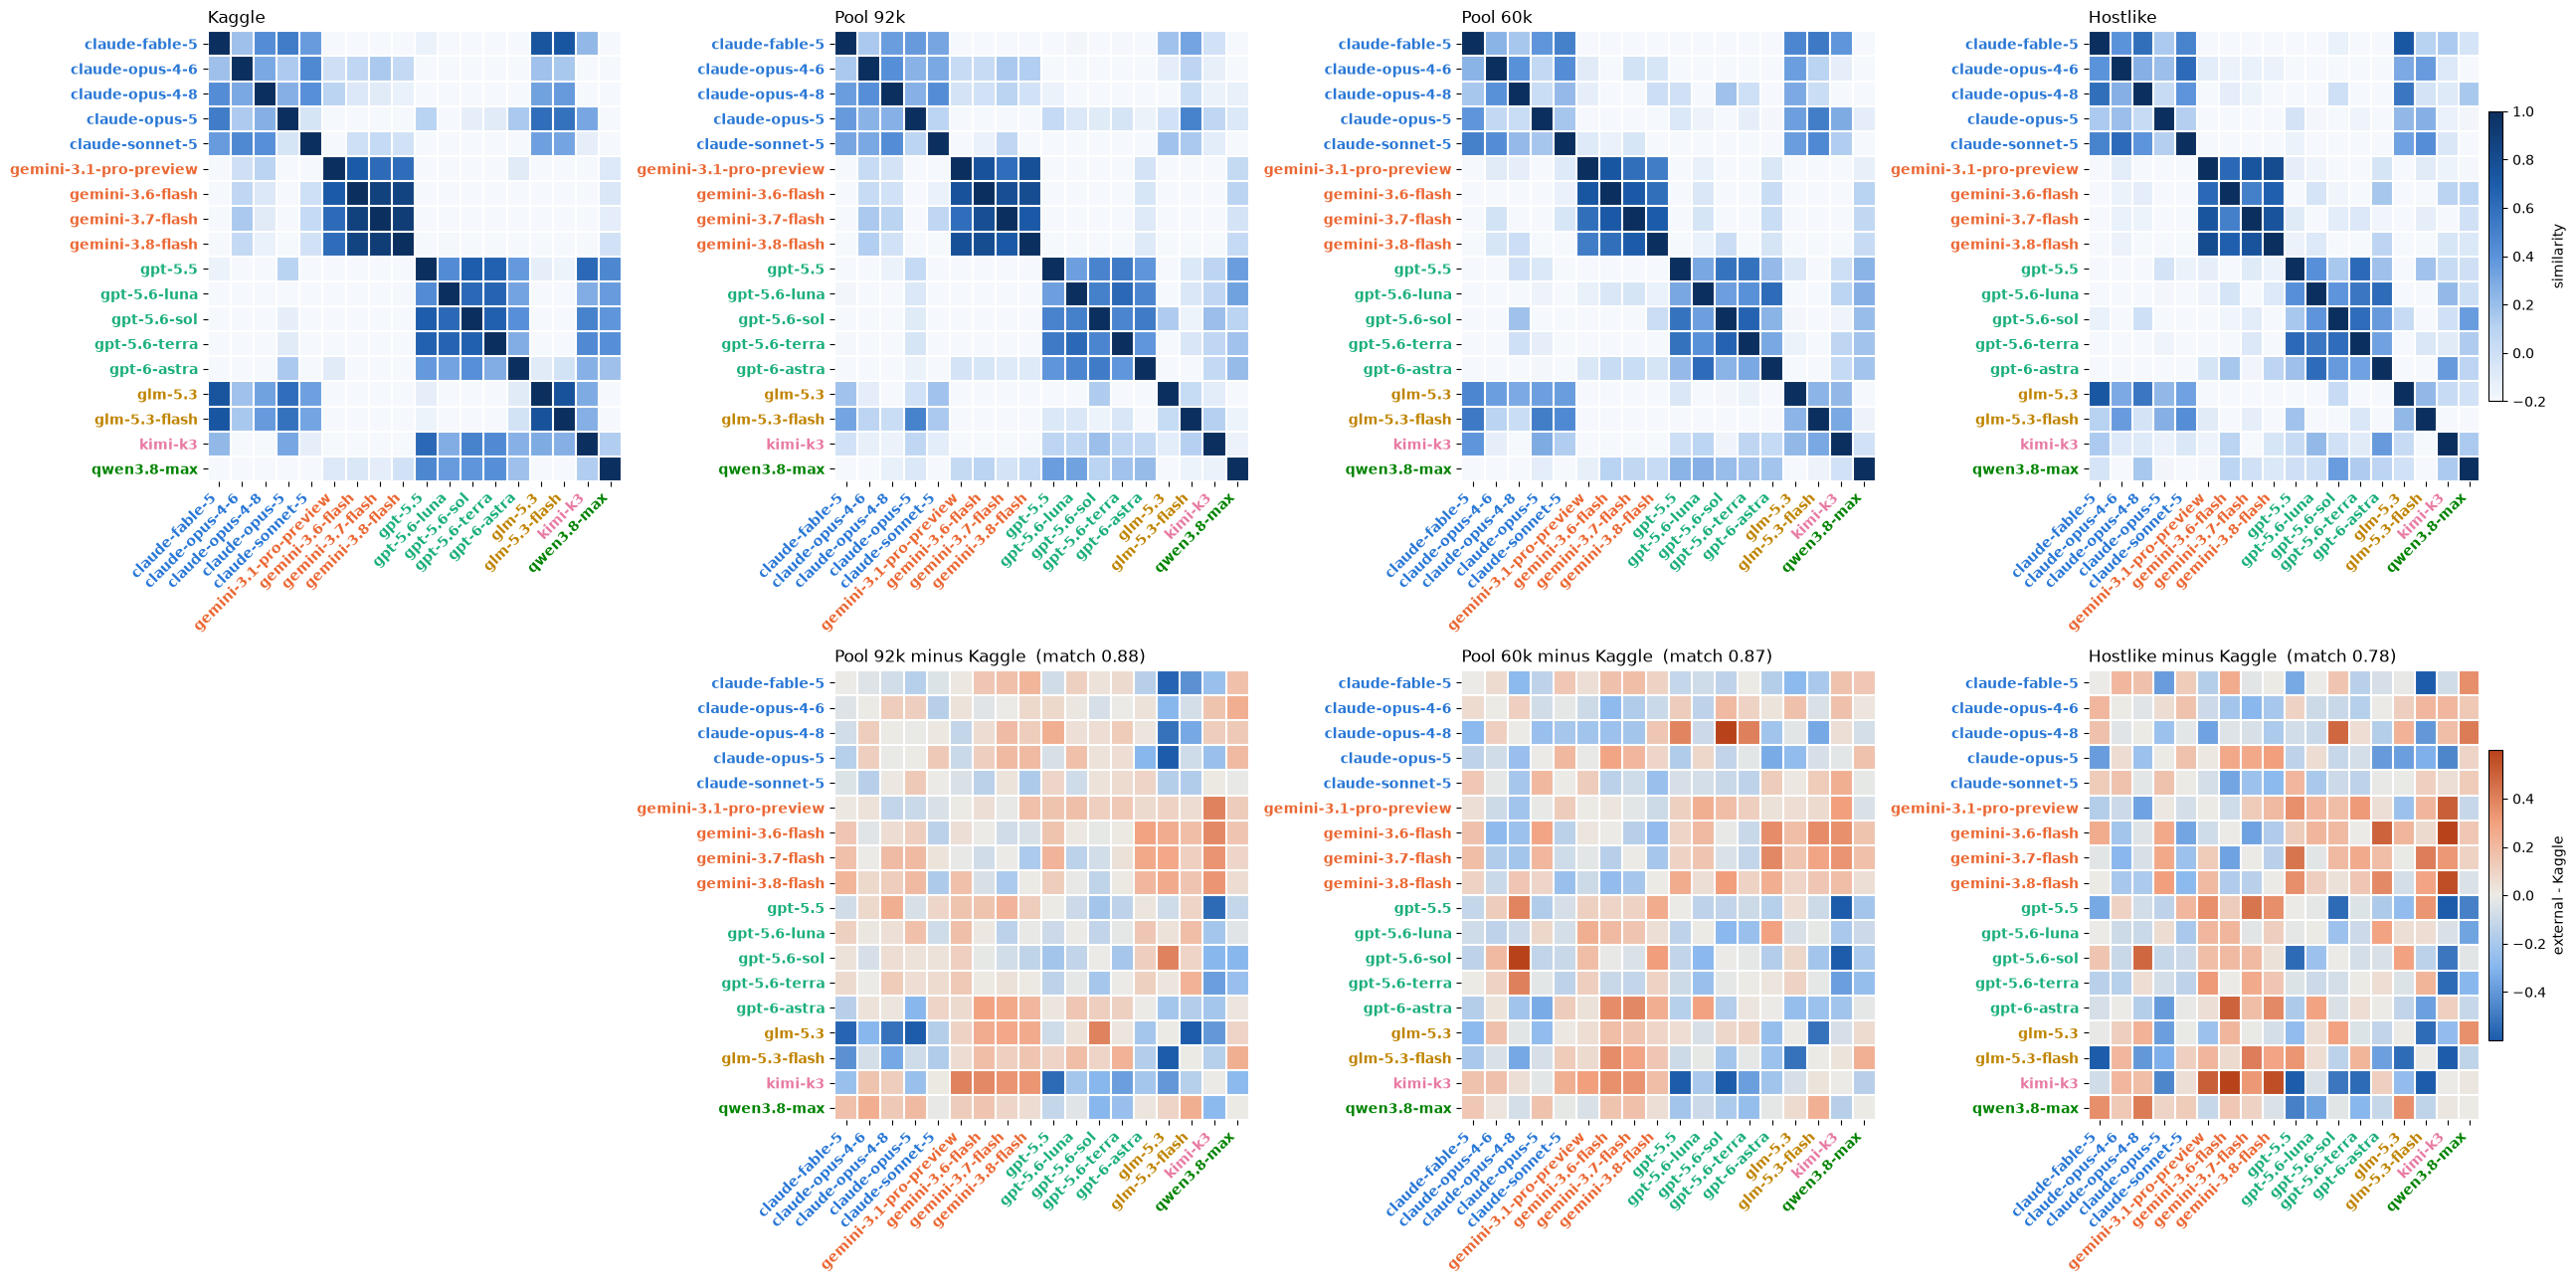

In [7]:
z = StandardScaler().fit(F["Kaggle"][VARY])
def sim(k):
    c = pd.DataFrame(z.transform(F[k][VARY]), index=S[k].model.values).groupby(level=0).mean().reindex(MODELS).to_numpy()
    c = c - c.mean(0)  # centre on this dataset's own average: an overall shift of a dataset is not "models alike"
    c = c / np.linalg.norm(c, axis=1, keepdims=True)
    return c @ c.T
SIM = {k: sim(k) for k in SETS}
fig, axes = plt.subplots(2, 4, figsize=(26, 13))
for ax, k in zip(axes[0], SETS):
    heat(ax, SIM[k], MODELS, MODELS, SEQ, vmin=-0.2, vmax=1, annot=False, cbar=(k == SETS[-1]), label="similarity")
    ax.set_title(k, loc="left")
axes[1, 0].axis("off")
iu = np.triu_indices(len(MODELS), 1)
for ax, k in zip(axes[1, 1:], EXT):
    heat(ax, SIM[k] - SIM["Kaggle"], MODELS, MODELS, DIV, norm=TwoSlopeNorm(0, -0.6, 0.6), annot=False,
         cbar=(k == EXT[-1]), label="external - Kaggle")
    ax.set_title(f"{k} minus Kaggle  (match {np.corrcoef(SIM[k][iu], SIM['Kaggle'][iu])[0, 1]:.2f})", loc="left")
plt.tight_layout(); plt.show()

**What this shows:**
- **The family map carries over:** the dark family squares (Claude, Gemini, GPT) are in every dataset, and the overall match is 0.88 (Pool 92k), 0.87 (Pool 60k) and 0.78 (hostlike).
- **Two Kaggle look-alikes fade outside**, and both match our known mistakes:
  - In Kaggle, **GLM looks like Claude** (dark GLM-Claude cells top-left). In Pool 92k that link is much weaker (blue in the "minus" panel).
  - In Kaggle, **Kimi looks like GPT**. Outside, much less (blue Kimi-GPT cells), while Kimi looks more like Gemini outside (orange).
- So the external data does not teach the Claude/GLM and Kimi/GPT confusions that happen in Kaggle; only Kaggle's own texts show them.

## 7. Do the clues that separate sibling models carry over?

This is the question that matters most for our score. Our worst mistakes are between **siblings** (models of the same family). For every sibling pair:
- **Kaggle separation**: how different the two models are in Kaggle (average absolute standardised difference over all style features). The **noise floor** column is the same number after shuffling the two models' labels: what pure chance gives with 150 texts each. If separation is close to the noise floor, our style features cannot tell the pair apart even in Kaggle.
- **Clue match** for each external set: the correlation between the pair's difference profile in Kaggle and outside. 1 = the same features separate them in the same direction; 0 = unrelated.

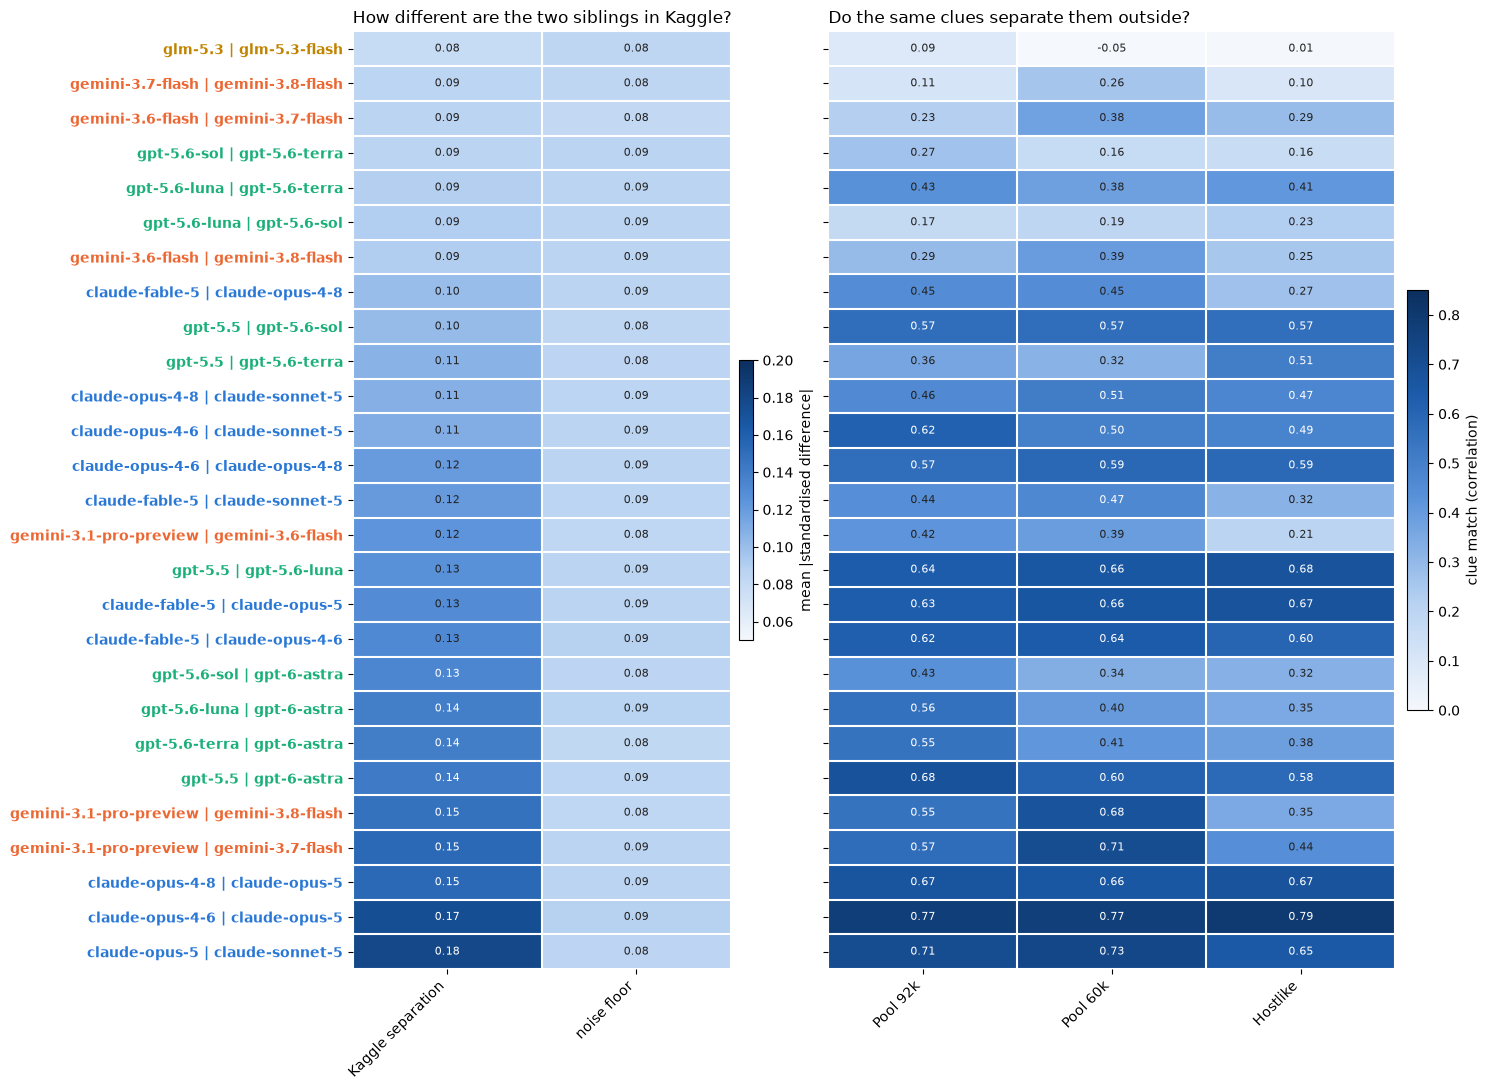

                                           Kaggle separation  noise floor  clue match Pool 92k  clue match Pool 60k  clue match Hostlike
pair                                                                                                                                    
glm-5.3 | glm-5.3-flash                                0.079        0.084                0.085               -0.047                0.006
gemini-3.7-flash | gemini-3.8-flash                    0.085        0.083                0.112                0.258                0.100
gemini-3.6-flash | gemini-3.7-flash                    0.086        0.082                0.226                0.376                0.288
gpt-5.6-sol | gpt-5.6-terra                            0.086        0.086                0.267                0.163                0.157
gpt-5.6-luna | gpt-5.6-terra                           0.089        0.086                0.430                0.379                0.411
gpt-5.6-luna | gpt-5.6-sol               

In [8]:
rng = np.random.default_rng(0)
K = F["Kaggle"][VARY].to_numpy(); KM = S["Kaggle"].model.to_numpy()
rows = []
for i, a in enumerate(MODELS):
    for b in MODELS[i + 1:]:
        if fam(a) != fam(b): continue
        ka, kb = K[KM == a], K[KM == b]
        t = smd(ka, kb)
        both = np.vstack([ka, kb]); noise = []
        for _ in range(20):
            p = rng.permutation(len(both)); noise.append(np.abs(smd(both[p[:len(ka)]], both[p[len(ka):]])).mean())
        r = {"pair": f"{a} | {b}", "Kaggle separation": np.abs(t).mean(), "noise floor": np.mean(noise)}
        for k in EXT:
            E = F[k][VARY].to_numpy(); EM = S[k].model.to_numpy()
            r[f"clue match {k}"] = np.corrcoef(t, smd(E[EM == a], E[EM == b]))[0, 1]
        rows.append(r)
SIB = pd.DataFrame(rows).set_index("pair")
SIB = SIB.sort_values("Kaggle separation")
fig, axes = plt.subplots(1, 2, figsize=(15, 11), gridspec_kw={"width_ratios": [2, 3]})
heat(axes[0], SIB[["Kaggle separation", "noise floor"]].values, list(SIB.index), ["Kaggle separation", "noise floor"],
     SEQ, vmin=0.05, vmax=0.2, label="mean |standardised difference|")
axes[0].set_title("How different are the two siblings in Kaggle?", loc="left")
cm = [c for c in SIB if c.startswith("clue")]
heat(axes[1], SIB[cm].values, list(SIB.index), [c.replace("clue match ", "") for c in cm], SEQ, vmin=0, vmax=0.85,
     label="clue match (correlation)")
axes[1].set_yticklabels([])
axes[1].set_title("Do the same clues separate them outside?", loc="left")
plt.tight_layout(); plt.show()
print(SIB.round(3).to_string())

**What this shows:**
- **Left:** for the top 7 pairs (glm-5.3 vs glm-5.3-flash, gemini-3.7 vs 3.8, gemini-3.6 vs 3.7 and 3.8, the gpt-5.6 luna / sol / terra trio), the Kaggle separation **equals the noise floor**. Our style features cannot tell these siblings apart **even in Kaggle**. Only the deep Qwen features, trained on Kaggle's own texts, can.
- **Right:** for exactly those pairs, the clue match is near 0 (0.1 to 0.4), as expected when there is no clue to carry over.
- For pairs that **do** differ in style (bottom half: Claude opus-5 vs others, gpt-5.5 / gpt-6-astra, gemini-3.1-pro vs the flashes), the clues carry over well (0.55 to 0.79), and both pools do better than hostlike.
- **Practical meaning:** the hardest mistakes are not caused by "bad" external data. They are between models that write almost identically, so more external data of the same kind will not fix them.

## 8. Does the external data teach what Kaggle's test needs?

A direct test, using only our style features and a simple classifier (logistic regression):
- **Taught by Kaggle**: trained on Kaggle, scored on Kaggle prompts it never saw (5 folds, split by prompt).
- **Taught by X**: trained only on 150 texts per model from external set X, scored on all of Kaggle.

Same model, same features, same amount of training data per model, so the only difference is where the training texts came from. Each heatmap cell is the share of Kaggle texts of that model (row) that were labelled as each model (column); a perfect classifier is a dark diagonal. The table after it shows the recall per model (diagonal) side by side.

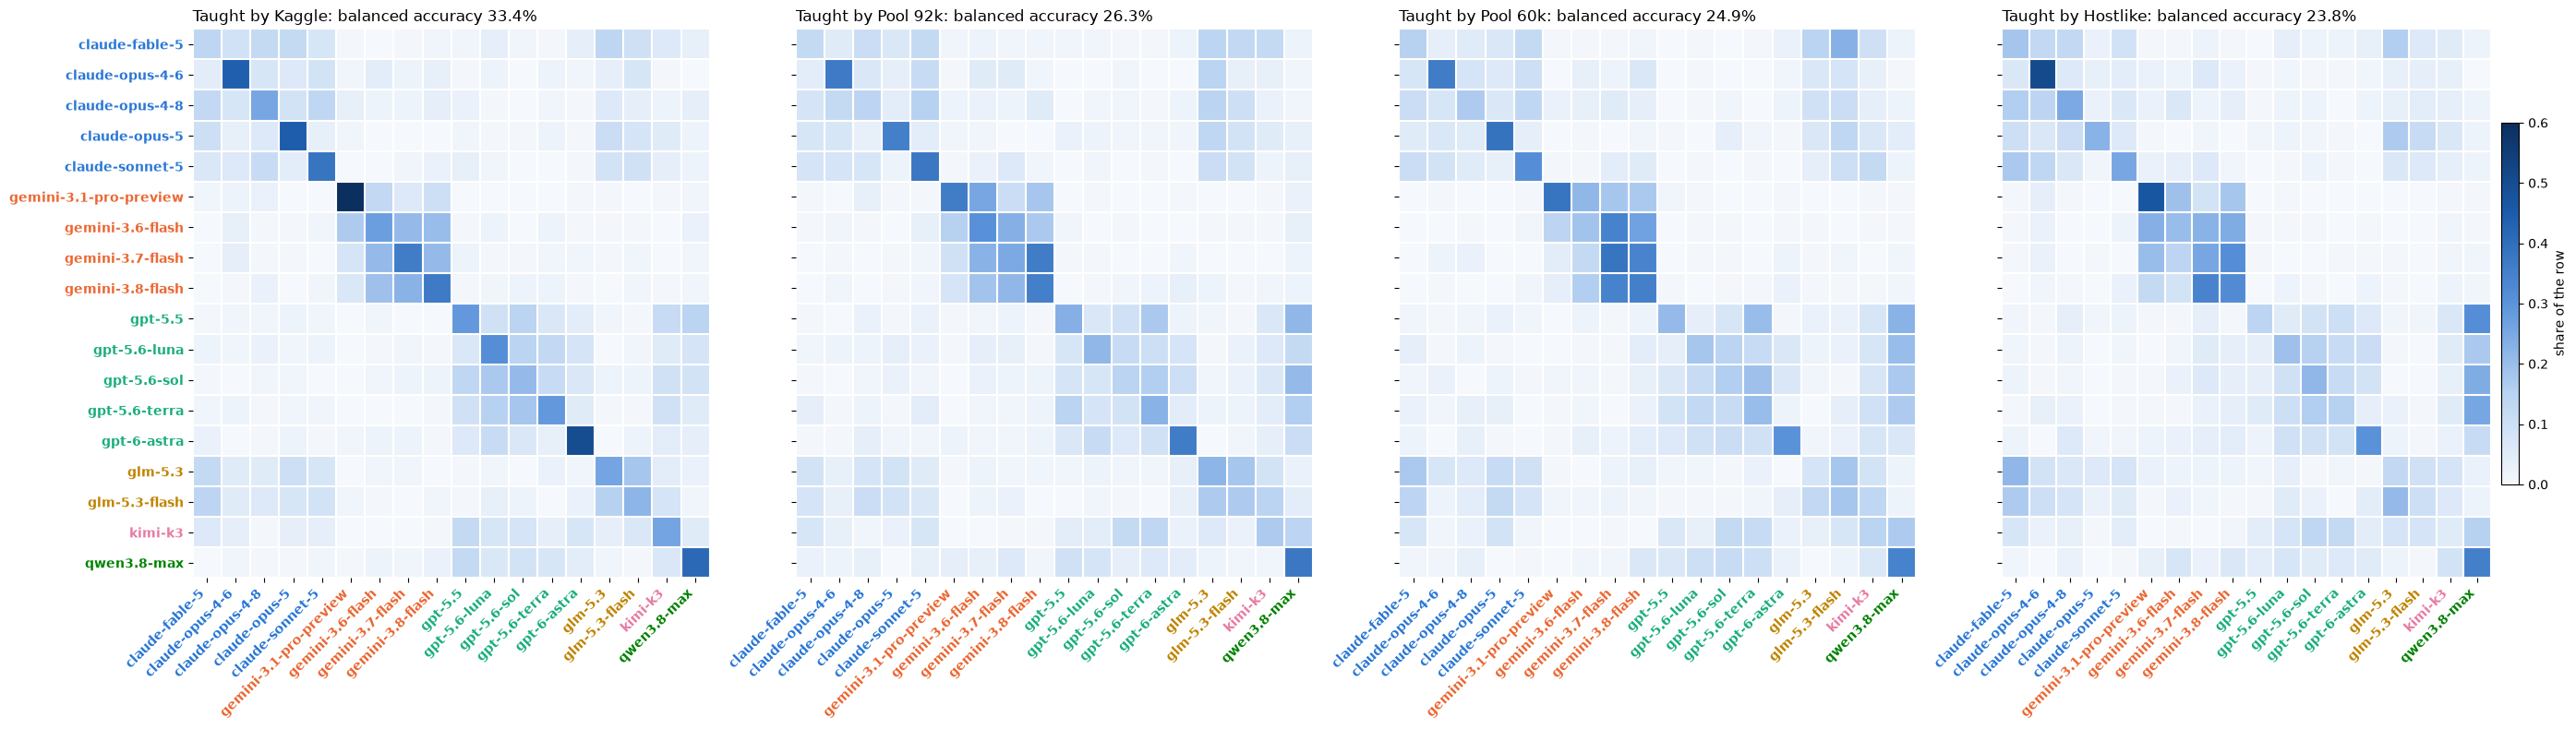

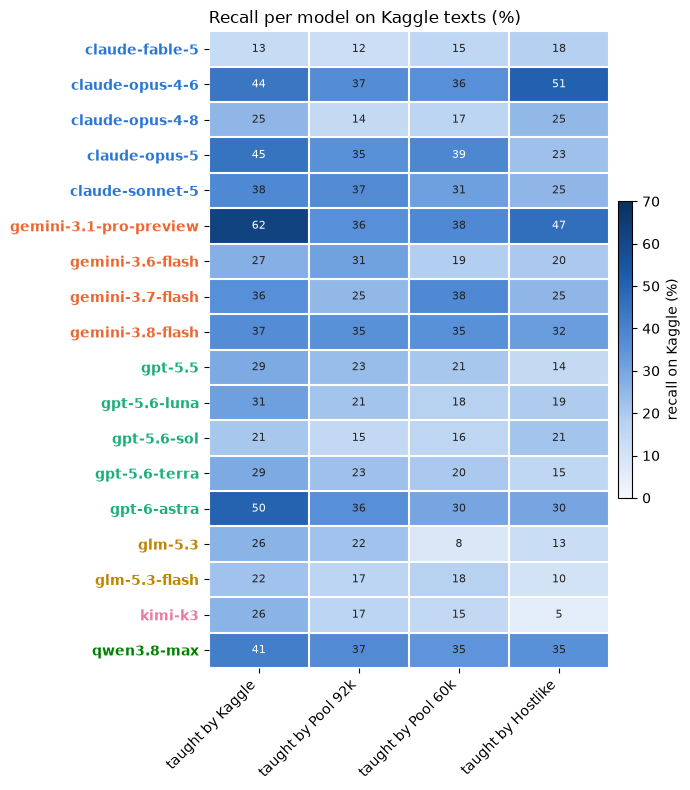

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
clf = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
Xk = np.log1p(F["Kaggle"][VARY].clip(lower=0)).to_numpy(); yk = S["Kaggle"].model.to_numpy()
pred = {"Kaggle": np.empty(len(yk), dtype=object)}
for tr_i, te_i in GroupKFold(5).split(Xk, yk, FULL["Kaggle"].prompt_id):
    pred["Kaggle"][te_i] = clf().fit(Xk[tr_i], yk[tr_i]).predict(Xk[te_i])
for k in EXT:
    pred[k] = clf().fit(np.log1p(F[k][VARY].clip(lower=0)).to_numpy(), S[k].model.to_numpy()).predict(Xk)
fig, axes = plt.subplots(1, 4, figsize=(28, 8), sharey=True)
REC = {}
for ax, k in zip(axes, SETS):
    cmx = confusion_matrix(yk, pred[k], labels=MODELS, normalize="true")
    REC[k] = np.diag(cmx)
    heat(ax, cmx, MODELS, MODELS, SEQ, vmin=0, vmax=0.6, annot=False, cbar=(k == SETS[-1]), label="share of the row")
    ax.set_title(f"Taught by {k}: balanced accuracy {100 * balanced_accuracy_score(yk, pred[k]):.1f}%", loc="left")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7, 8))
R = pd.DataFrame(REC, index=MODELS)
heat(ax, R.values * 100, MODELS, [f"taught by {k}" for k in SETS], SEQ, vmin=0, vmax=70, fmt="{:.0f}",
     label="recall on Kaggle (%)")
ax.set_title("Recall per model on Kaggle texts (%)", loc="left"); plt.tight_layout(); plt.show()

**What this shows:**
- **Kaggle texts are worth more than external texts:** with the same 150 texts per model, training on Kaggle gives **33.4%**, on Pool 92k **26.3%**, Pool 60k **24.9%**, hostlike **23.8%** (on prompts the Kaggle model never saw). About 7 to 10 points are lost purely from where the training texts came from.
- **Biggest losses** when taught by external data: gemini-3.1-pro (62% down to 36% to 47%), gpt-6-astra (50% down to 30% to 36%), kimi-k3 (26% down to 5% to 17%), glm-5.3 (26% down to 8% to 22%).
- **A new confusion appears:** taught by external data, many Kaggle GPT texts are labelled **qwen3.8-max** (the lit qwen column in the GPT rows). Outside, Qwen writes more like Kaggle's GPT.
- Pool 92k is the best of the three external teachers, which agrees with the main model (trained on it first) being our strongest member.
- This is why stage 2 on Kaggle's own texts matters so much, and why the 3 to 4 points we lose on the hidden test are hard to win back with more outside data.

## 9. Can a classifier tell the datasets apart?

Here a classifier gets mixed Kaggle and external texts (class-matched) and must guess **which dataset** each text came from. The score is AUC: **0.5 = it cannot tell (the data look the same)**, 1.0 = it is never wrong.
- **Style features**: our 290 hand-made style numbers only.
- **Character patterns**: 2 to 4 character snippets (TF-IDF), which also see the topic and vocabulary.

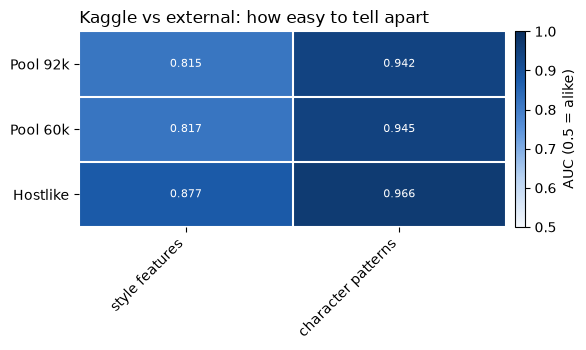

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
cv = StratifiedKFold(5, shuffle=True, random_state=0)
A = {}
for k in EXT:
    y = np.r_[np.zeros(len(S["Kaggle"])), np.ones(len(S[k]))]
    Xs = np.log1p(pd.concat([F["Kaggle"][VARY], F[k][VARY]]).clip(lower=0)).to_numpy()
    p1 = cross_val_predict(clf(), Xs, y, cv=cv, method="predict_proba")[:, 1]
    Xc = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=3, max_features=100_000,
                         sublinear_tf=True).fit_transform(pd.concat([S["Kaggle"].text, S[k].text]))
    p2 = cross_val_predict(LogisticRegression(C=1.0, max_iter=2000), Xc, y, cv=cv, method="predict_proba")[:, 1]
    A[k] = {"style features": roc_auc_score(y, p1), "character patterns": roc_auc_score(y, p2)}
A = pd.DataFrame(A).T
fig, ax = plt.subplots(figsize=(6, 3.6))
heat(ax, A.values, list(A.index), list(A.columns), SEQ, vmin=0.5, vmax=1.0, fmt="{:.3f}", label="AUC (0.5 = alike)")
ax.set_title("Kaggle vs external: how easy to tell apart", loc="left"); plt.tight_layout(); plt.show()

**What this shows:**
- **Easy to tell apart.** Even with only style numbers, a classifier picks the dataset with AUC 0.82 (pools) and 0.88 (hostlike). With character patterns, which see topics and vocabulary, 0.94 to 0.97.
- That fits sections 4 and 5: no single feature differs much, but many small shifts add up, and the topics differ completely (the external sets were built to avoid Kaggle's prompts).

## Summary

| Question | Pool 92k | Pool 60k | Hostlike |
|---|---|---|---|
| Model mix like Kaggle? | uneven (opus-5, gemini-3.7, qwen short) | yes, balanced | uneven (GPT heavy, Gemini short) |
| Length like Kaggle? | yes (101 vs 101 words) | yes (100) | shorter (86) |
| Features drifting > 0.5 sd | 1.5% | 1.4% | 4.6% |
| Family map match | 0.88 | 0.87 | 0.78 |
| Tell-apart AUC (style / characters) | 0.82 / 0.94 | 0.82 / 0.95 | 0.88 / 0.97 |
| Classifier taught on it, scored on Kaggle | 26.3% | 24.9% | 23.8% (Kaggle-taught 33.4%) |

**In one line:** the external data looks like Kaggle on average and teaches the families correctly, but the details differ:
- GPT sentence length and Kimi semicolons;
- the 3.7 vs 3.8 length clue;
- the GLM-like-Claude and Kimi-like-GPT resemblance.

Our hardest siblings write almost identically even in Kaggle. Kaggle's own texts remain the best teacher, and Pool 92k is the best external one.